# PLXY-AI: automated xylem cell detection and morphometrics — minimal reproduction

**Paper:** *Toward scalable wood anatomy: a toolkit for automated xylem cell identification and quantification in woody angiosperms*, Plant Physiology 201(2), article kiag324 (2026). DOI: [10.1093/plphys/kiag324](https://doi.org/10.1093/plphys/kiag324)

**Author code:** [`xueping2025/PLXY-AI`](https://github.com/xueping2025/PLXY-AI) pinned at commit `ba33be63482fca2d8528cdace05e431b8ee7f77c` (verified 2026-10-26).

## Scope (partial demonstration)

This notebook reproduces **one minimal, scientifically faithful unit** of the paper's toolkit: per-class **YOLOv8n detection of vessels and fibres** on **one** wood-section microscopy image bundled by the authors (`PLXY AI/Input/94307.jpg`), followed by the authors' **per-cell morphometric extraction** (width / height / diameter / area). The segmentation-then-detection pipeline, the Mask2Former semantic-segmentation path, model benchmarking, training, and the full 1,790-image dataset are **out of scope**.

**AI-assisted note (EN):** The authors provide the analysis as a PySide6 GUI plus standalone scripts, not as a Colab notebook. The pipeline cells below are a faithful port of the authors' pinned script `PLXY AI/yolo_detect/batch_detectcode/radioButton_SingleCell/radioButton_20X/Vessel.py` (logic copied, cited inline); glue cells (download, display, CSV) are new. The executed example was validated, but untested behavior is not guaranteed.

**AI 補足 (JA):** 著者は GUI およびスタンドアロンの Python スクリプトで解析を提供しており、Colab ノートブックは付属しません。本ノートブックは著者のピン留め済みスクリプト（commit `ba33be6`）の処理を忠実に移植したものです。実行例は検証済みですが、未検証の動作は保証されません。

**Expected runtime:** ~5–10 minutes total on a free **CPU** Colab runtime (no GPU needed); ~14 MB of downloads. Run all cells top to bottom (`Runtime → Run all`).

## 1. Runtime selection

This demo performs inference with **YOLOv8n** (≈3.2 M parameters) on a single ~1.5 MB JPEG. On CPU this takes seconds, so a standard **CPU runtime is recommended**; a GPU (T4) also works but is unnecessary. No CUDA-only operations are used.

**Japanese:** YOLOv8n（約320万パラメータ）による1枚の推論はCPUで数秒です。**CPU ランタイムで十分**です（GPUは不要、ただし使用しても可）。メニューの「ランタイム → すべてのセルを実行」で実行してください。

In [ ]:
import os, platform, sys

print("Python:", sys.version)
print("Platform:", platform.platform())
print("CPU count:", os.cpu_count())
print("Working dir:", os.getcwd())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
CPU count: 2
Working dir: /content


## 2. Install the model library

The authors vendor **ultralytics 8.2.49** inside the repository (`PLXY AI/yolo_detect/ultralytics/__init__.py`), so we pin the same version for fidelity. We install it with `--no-deps`: Colab already provides every runtime dependency (torch, numpy 2.x, OpenCV, matplotlib, pandas), and ultralytics 8.2.49's declared `numpy<2.0` pin would force a slow source-built numpy downgrade that cannot take effect in the already-running kernel and breaks binary compatibility of preinstalled packages. Only the tiny `ultralytics-thop` FLOPs counter is added explicitly.

**Japanese:** 著者が同梱した **ultralytics 8.2.49** にバージョンを固定します。Colab には実行に必要なライブラリが全て揃っているため `--no-deps` でインストールし（numpy の不要なダウングレードを回避）、軽量な `ultralytics-thop` のみ明示的に追加します。

In [ ]:
%pip install -q --no-deps "ultralytics==8.2.49" "ultralytics-thop>=2.0.0"

## 3. Verify the environment

Report the installed torch/ultralytics versions and the allocated device. The notebook works identically on CPU or GPU; the device is only reported, never required.

**Japanese:** torch と ultralytics のバージョン、割り当てられたデバイス（CPU または GPU）を表示します。処理自体はどちらのデバイスでも同一です。

In [ ]:
import torch, ultralytics

print("torch:", torch.__version__)
print("ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

torch: 2.11.0+cpu
ultralytics: 8.2.49
CUDA available: False
Using device: cpu


## 4. Acquire the pinned sample image and weights (inside Colab only)

Download exactly three files from the author repository at the pinned commit `ba33be6` via `raw.githubusercontent.com`:

| file | role | size (B) | git blob SHA-1 |
| --- | --- | --- | --- |
| `PLXY AI/Input/94307.jpg` | sample transverse section | 1,469,210 | `0d857d95297c4dd0a8dcc3a9cf936409b358bc94` |
| `PLXY AI/weight/Vessel/Vessel-YOLOv8n.pt` | vessel detector weights | 6,280,675 | `0b448a2353ab41a1b62d599ec222f2ae936fab6a` |
| `PLXY AI/weight/Fibre/Fibre-YOLOv8n.pt` | fibre detector weights | 6,333,667 | `593a5f4e2962707566e04200073bf9f9072ee53e` |

Each download is verified against its recorded byte size and **git blob SHA-1** (computed as `sha1("blob <size>\0" + content)`), and Git-LFS pointer text is rejected.

**Japanese:** 著者リポジトリの pinned commit から、サンプル画像1枚と重み2つ（計約14 MB）を Colab 内にのみダウンロードし、バイト数と git blob SHA-1 で検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path
from urllib.parse import quote

COMMIT = "ba33be63482fca2d8528cdace05e431b8ee7f77c"
REPO = "xueping2025/PLXY-AI"
RAW_BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"
OUT_DIR = Path("/content/plxy_ai")

# (local name, repo path, expected size, expected git blob SHA-1)
PINNED_FILES = {
    "94307.jpg": ("PLXY AI/Input/94307.jpg", 1469210,
                  "0d857d95297c4dd0a8dcc3a9cf936409b358bc94"),
    "Vessel-YOLOv8n.pt": ("PLXY AI/weight/Vessel/Vessel-YOLOv8n.pt", 6280675,
                          "0b448a2353ab41a1b62d599ec222f2ae936fab6a"),
    "Fibre-YOLOv8n.pt": ("PLXY AI/weight/Fibre/Fibre-YOLOv8n.pt", 6333667,
                         "593a5f4e2962707566e04200073bf9f9072ee53e"),
}

OUT_DIR.mkdir(parents=True, exist_ok=True)

def git_blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for local_name, (repo_path, expected_size, expected_sha) in PINNED_FILES.items():
    url = f"{RAW_BASE}/{quote(repo_path)}"
    dest = OUT_DIR / local_name
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    data = dest.read_bytes()
    assert len(data) == expected_size, f"{local_name}: size {len(data)} != {expected_size}"
    assert not data.lstrip().startswith(b"version https://git-lfs"), f"{local_name}: LFS pointer"
    actual_sha = git_blob_sha1(data)
    assert actual_sha == expected_sha, f"{local_name}: blob sha {actual_sha} != {expected_sha}"
    print(f"OK  {local_name:22s} {len(data):>9,} B  blob {actual_sha[:12]}...")

IMAGE_PATH = OUT_DIR / "94307.jpg"
VESSEL_WEIGHTS = str(OUT_DIR / "Vessel-YOLOv8n.pt")
FIBRE_WEIGHTS = str(OUT_DIR / "Fibre-YOLOv8n.pt")

OK  94307.jpg              1,469,210 B  blob 0d857d95297c...


OK  Vessel-YOLOv8n.pt      6,280,675 B  blob 0b448a2353ab...


OK  Fibre-YOLOv8n.pt       6,333,667 B  blob 593a5f4e2962...


## 5. Load the per-class detectors

Instantiate the author's two `YOLOv8n` checkpoints exactly as the pinned scripts do (`YOLO(weight_file)`) and print each model's task and class names. Both are single-class detectors trained by the authors for poplar xylem.

**Compatibility adaptation (AI-generated, documented):** PyTorch ≥ 2.6 changed `torch.load` to default `weights_only=True`, which the authors' pinned ultralytics 8.2.49 predates. We restore the legacy default **only after** the checkpoint bytes were verified against their git blob SHA-1 in section 4. Verified 2026-10-26 on Colab (torch 2.11, CPU).

**Japanese:** 著者のスクリプトと同様に `YOLO(weight_file)` で2つの検出器を読み込み、タスクとクラス名を確認します。PyTorch 2.6 以降の `torch.load` 既定変更（`weights_only=True`）に対応するため、チェックポイントの完全性を git blob SHA-1 で検証した後に旧既定へ戻す限定的な互換パッチを適用します（Colab の torch 2.11 / CPU で検証済み）。

In [ ]:
import functools
from ultralytics import YOLO

# Compatibility patch (see markdown above): pre-2.6 torch.load default for verified checkpoints.
torch.load = functools.partial(torch.load, weights_only=False)

vessel_model = YOLO(VESSEL_WEIGHTS)
fibre_model = YOLO(FIBRE_WEIGHTS)

for name, m in [("vessel", vessel_model), ("fibre", fibre_model)]:
    print(name, "| task:", m.task, "| names:", m.names)

vessel | task: detect | names: {0: 'Vessel'}
fibre | task: detect | names: {0: 'fibre'}


## 6. Preview the input image

Show the raw sample (`94307.jpg`) with its dimensions before any analysis. This is a transverse (cross-section) wood microscopy image of poplar xylem, bundled by the authors as toolkit input.

**Japanese:** 解析前にサンプル画像 `94307.jpg`（ポプラ横断面の顕微鏡画像）をそのまま表示し、画像サイズを確認します。

Image dimensions: 4080 x 3072 px, 3 channel(s)


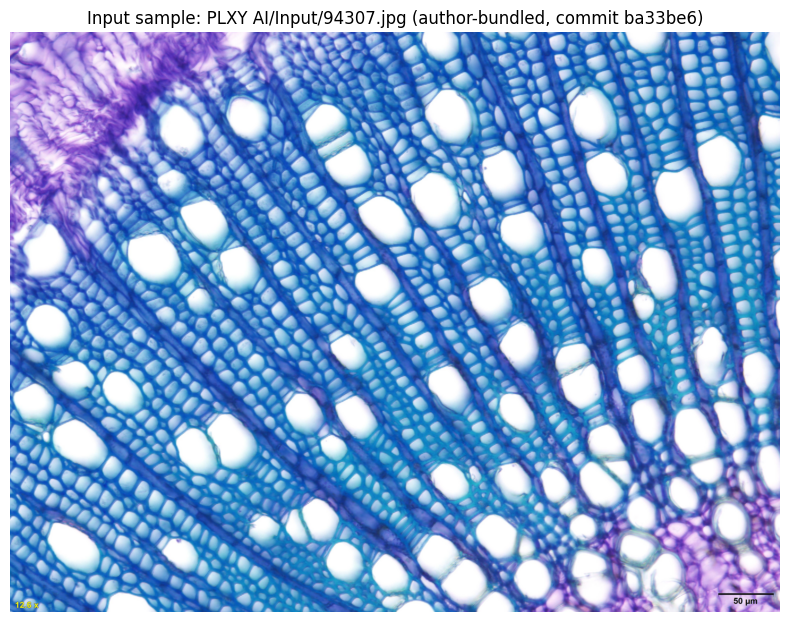

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_UNCHANGED)
assert image_bgr is not None, "cv2 could not decode the sample image"
H, W = image_bgr.shape[:2]
print(f"Image dimensions: {W} x {H} px, {image_bgr.shape[2] if image_bgr.ndim == 3 else 1} channel(s)")

plt.figure(figsize=(10, 10 * H / W))
plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Input sample: PLXY AI/Input/94307.jpg (author-bundled, commit ba33be6)")
plt.show()

## 7. Core method: vessel detection and morphometric extraction

The function below is a faithful port of the author's pinned pipeline in
`PLXY AI/yolo_detect/batch_detectcode/radioButton_SingleCell/radioButton_20X/Vessel.py` (lines ~22–60):

1. `results = model(image)` — YOLOv8 inference (default confidence 0.25; `max_det=3000` follows the authors' `detect_code/Vessel/vessel_count.py` to avoid silently truncating dense detections);
2. sort detections by center-y, then center-x (author's ordering);
3. per cell: bbox width/height in pixels, converted with `pixel_to_micron = 50 / 293` (the authors' **20X** calibration constant) to width, height, `diameter = max(w, h)`, and `area = w × h` in µm / µm².

**Calibration caveat (also in JA below):** the authors' GUI lets the user pick the objective (4X: `20/234`, 10X: `100/293`, 20X: `50/293` µm/px). The magnification of the bundled sample images is not documented in accessible sources, so this notebook uses the authors' **20X** constant; counts and pixel shapes are magnification-independent, and switching the constant only rescales the µm columns.

**Japanese:** 著者のピン留め済みスクリプト（SingleCell/20X `Vessel.py`）の処理をそのまま移植しました。検出（既定 confidence 0.25、`max_det=3000` は著者の `vessel_count.py` に準拠）→ 中心座標ソート → 20X較正定数 `50/293` µm/px による形質抽出（幅・高さ・直径・断面積）。付属サンプルの倍率は公開資料からは確認できないため、20X 定数を明示的に使用しています（個数・ピクセル値は倍率に依存しません）。

In [ ]:
import pandas as pd

# 20X calibration from the authors' pinned 20X Vessel.py (4X: 20/234, 10X: 100/293)
PIXEL_TO_MICRON = 50 / 293

def detect_and_measure(model, image_bgr, pixel_to_micron, label):
    """Faithful port of the author's SingleCell 20X Vessel.py detect_vessels() pipeline."""
    results = model.predict(image_bgr, max_det=3000)[0]  # author: max_det=3000 in detect_code
    boxes = results.boxes.xyxy.cpu().numpy()
    detections = sorted(boxes, key=lambda x: (x[1] + x[3]) / 2)   # author: sort by center y
    detections = sorted(detections, key=lambda x: (x[0] + x[2]) / 2)  # then center x
    rows = []
    for i, det in enumerate(detections):
        x_min, y_min, x_max, y_max = map(int, det[:4])
        w, h = x_max - x_min, y_max - y_min
        rows.append({
            "Image": label,
            "Cell Number": i + 1,
            "Width (px)": w,
            "Height (px)": h,
            "Width (microns)": w * pixel_to_micron,       # author formulas below, verbatim
            "Height (microns)": h * pixel_to_micron,
            "Diameter (microns)": max(w, h) * pixel_to_micron,
            "Area (square microns)": (w * h) * (pixel_to_micron ** 2),
        })
    return results, pd.DataFrame(rows)

vessel_results, vessel_df = detect_and_measure(vessel_model, image_bgr, PIXEL_TO_MICRON, "94307.jpg")
print(f"Vessels detected: {len(vessel_df)}")
vessel_df.head(10)

0: 512x640 87 Vessels, 394.2ms


Speed: 23.2ms preprocess, 394.2ms inference, 35.6ms postprocess per image at shape (1, 3, 512, 640)


Vessels detected: 87


,Image,Cell Number,Width (px),Height (px),Width (microns),Height (microns),Diameter (microns),Area (square microns)
0,94307.jpg,1,216,220,36.860068,37.542662,37.542662,1383.825088
1,94307.jpg,2,246,291,41.979522,49.658703,49.658703,2084.648627
2,94307.jpg,3,236,233,40.273038,39.761092,40.273038,1601.299957
3,94307.jpg,4,225,200,38.395904,34.129693,38.395904,1310.440424
4,94307.jpg,5,280,264,47.781570,45.051195,47.781570,2152.616804
5,94307.jpg,6,295,263,50.341297,44.880546,50.341297,2259.344896
6,94307.jpg,7,215,223,36.689420,38.054608,38.054608,1396.201470
7,94307.jpg,8,246,102,41.979522,17.406143,41.979522,730.701581
8,94307.jpg,9,280,269,47.781570,45.904437,47.781570,2193.386062
9,94307.jpg,10,160,159,27.303754,27.133106,27.303754,740.835653


## 8. Vessel overlay and measurements

Draw the annotated image in the author's exact style (green boxes, blue index numbers, red count text — BGR color order preserved from the author's OpenCV code) and show the full measurement table. This overlay is a **model prediction**, not a reference annotation.

**Japanese:** 著者のコードと同じ描画スタイル（緑の矩形・青の番号・赤のカウント、BGR の順は元コードのまま）で検出結果を重畳表示します。これは**モデルの予測**であり、正解アノテーションではありません。

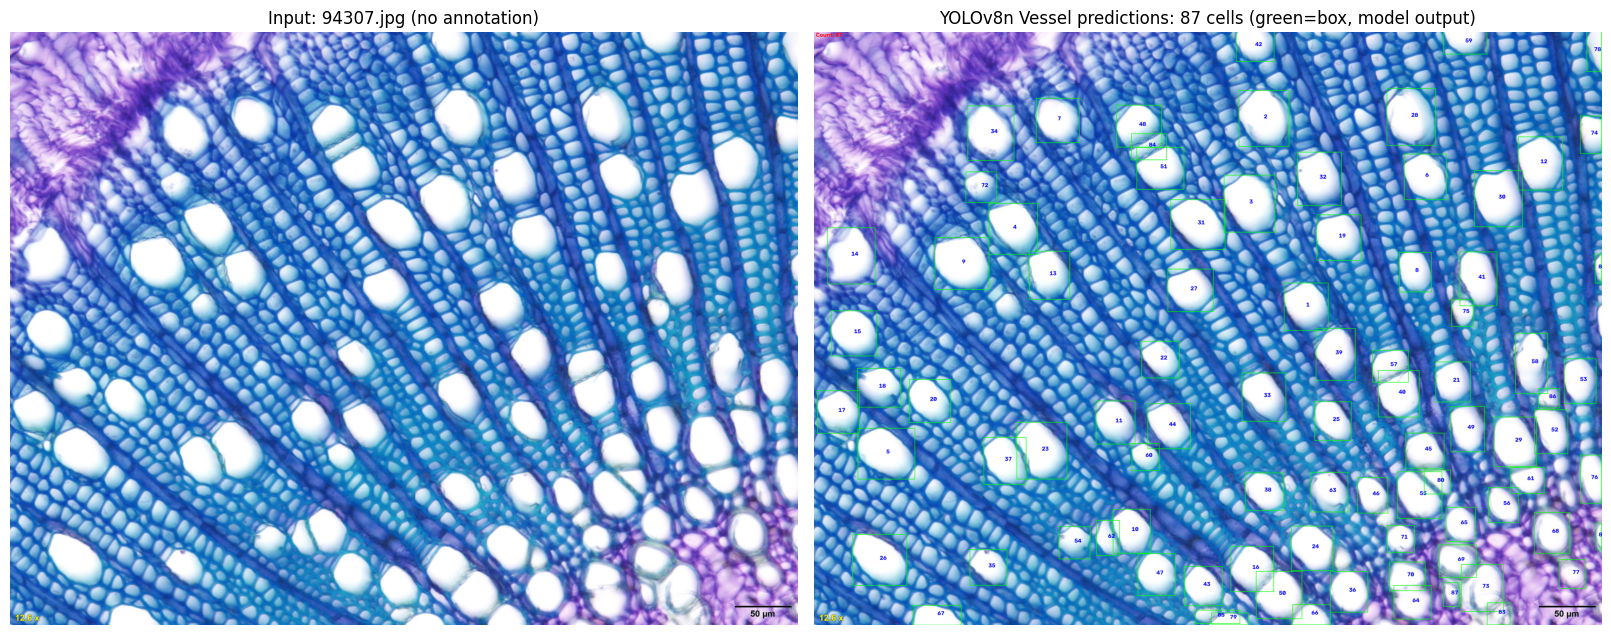

,Width (microns),Height (microns),Diameter (microns),Area (square microns)
count,87.000000,87.000000,87.000000,87.000000
mean,33.197991,35.332078,37.460280,1219.202307
std,8.824849,9.663569,7.935926,553.133270
min,5.119454,10.580205,18.771331,120.560519
25%,28.924915,28.668942,32.764505,785.798320
50%,33.447099,37.030717,38.395904,1186.385398
75%,38.993174,41.808874,41.894198,1566.879055
max,50.341297,53.071672,53.071672,2259.344896


In [ ]:
def draw_author_overlay(image_bgr, results):
    """Author's drawing style from SingleCell/20X/Vessel.py (BGR colors preserved)."""
    img = image_bgr.copy()
    boxes = results.boxes.xyxy.cpu().numpy()
    for i, det in enumerate(boxes):
        x_min, y_min, x_max, y_max = map(int, det[:4])
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
        cv2.putText(img, str(i + 1), ((x_min + x_max) // 2, (y_min + y_max) // 2),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    cv2.putText(img, f"Count: {len(boxes)}", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    return img

vessel_overlay_bgr = draw_author_overlay(image_bgr, vessel_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), constrained_layout=True)
axes[0].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input: 94307.jpg (no annotation)")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(vessel_overlay_bgr, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"YOLOv8n Vessel predictions: {len(vessel_df)} cells (green=box, model output)")
axes[1].axis("off")
plt.show()

vessel_df.describe()[["Width (microns)", "Height (microns)", "Diameter (microns)", "Area (square microns)"]]

## 9. Fibre detection on the same sample

Run the identical pipeline with the authors' `Fibre-YOLOv8n.pt` checkpoint (fibres are much more numerous and smaller than vessels). Same calibration constant and table columns as above.

**Japanese:** 同じサンプルに `Fibre-YOLOv8n.pt` で同一の処理（較正定数・列も同じ）を適用します。繊維（fibre）は導管より小さく数が多くなります。

0: 512x640 1237 fibres, 157.5ms


Speed: 5.3ms preprocess, 157.5ms inference, 11.1ms postprocess per image at shape (1, 3, 512, 640)


Fibres detected: 1237


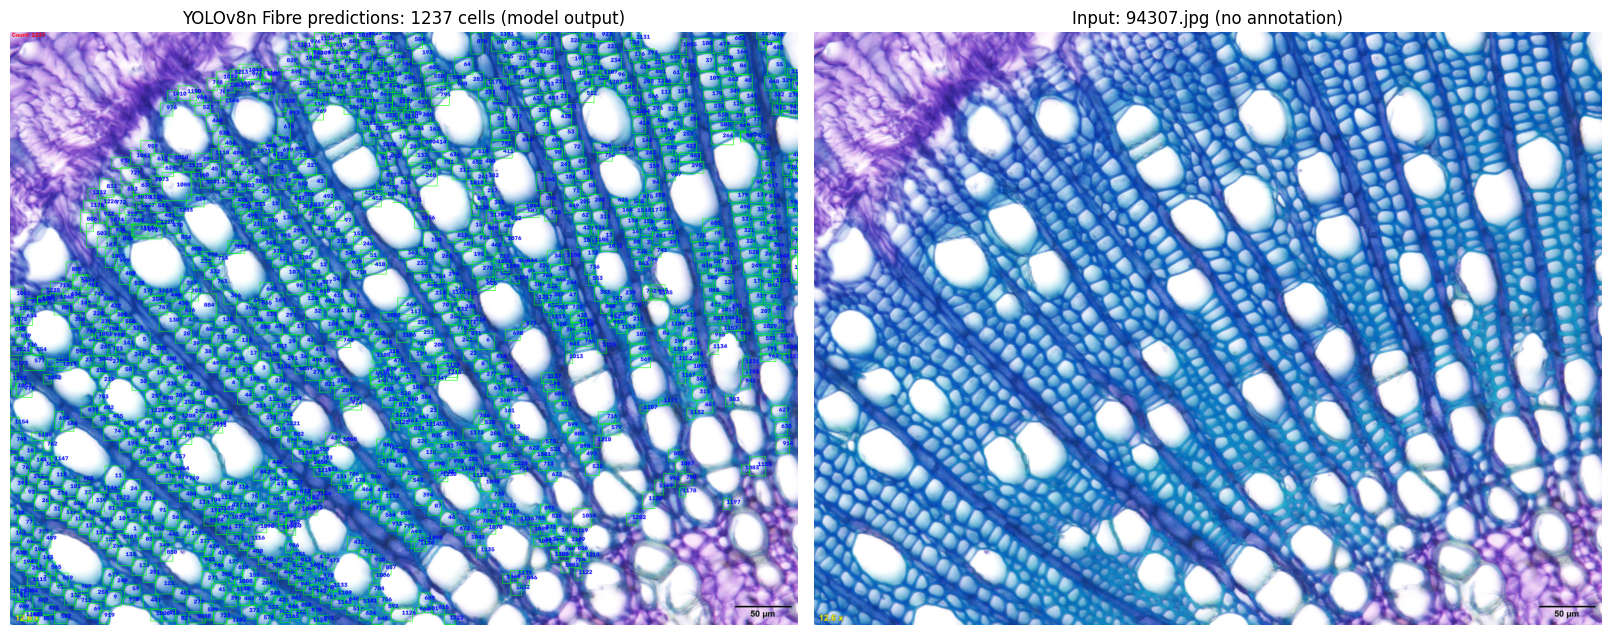

,Width (microns),Height (microns),Diameter (microns),Area (square microns)
count,1237.000000,1237.000000,1237.000000,1237.000000
mean,10.655941,10.556339,11.706043,117.143534
std,3.134582,2.854475,3.012406,58.898006
min,3.754266,3.242321,5.119454,21.665948
25%,8.361775,8.361775,9.556314,74.695104
50%,10.409556,10.409556,11.433447,108.242379
75%,12.627986,12.286689,13.651877,148.400098
max,25.597270,24.914676,25.597270,637.747673


In [ ]:
fibre_results, fibre_df = detect_and_measure(fibre_model, image_bgr, PIXEL_TO_MICRON, "94307.jpg")
print(f"Fibres detected: {len(fibre_df)}")

fibre_overlay_bgr = draw_author_overlay(image_bgr, fibre_results)

fig, axes = plt.subplots(1, 2, figsize=(16, 9), constrained_layout=True)
axes[0].imshow(cv2.cvtColor(fibre_overlay_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"YOLOv8n Fibre predictions: {len(fibre_df)} cells (model output)")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
axes[1].set_title("Input: 94307.jpg (no annotation)")
axes[1].axis("off")
plt.show()

fibre_df[["Width (microns)", "Height (microns)", "Diameter (microns)", "Area (square microns)"]].describe()

## 10. Summary table and CSV export

Combine per-class summary statistics (count, median diameter, mean area — magnification-dependent columns use the 20X assumption stated above) and export the full per-cell tables as CSV under `/content/plxy_ai/results/`, mirroring the authors' spreadsheet export (the authors write `.xlsx`; the notebook uses `.csv` purely to avoid an extra dependency — the columns match the author's file).

**Japanese:** クラス別の統計（個数・直径の中央値・平均断面積）をまとめ、セルごとの全計測値を CSV に保存します。著者は xlsx 出力ですが、列定義は同一です（依存を避けるため CSV を使用）。

In [ ]:
summary = pd.DataFrame([
    {
        "Class": cls,
        "Cells detected": len(df),
        "Median diameter (microns)": round(df["Diameter (microns)"].median(), 3),
        "Mean area (square microns)": round(df["Area (square microns)"].mean(), 3),
        "Total area (square microns)": round(df["Area (square microns)"].sum(), 3),
    }
    for cls, df in [("Vessel", vessel_df), ("Fibre", fibre_df)]
])
print(summary.to_string(index=False))

results_dir = OUT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)
vessel_df.to_csv(results_dir / "vessel20X_detection_results.csv", index=False)
fibre_df.to_csv(results_dir / "fibre20X_detection_results.csv", index=False)
print("\nSaved:")
for p in sorted(results_dir.glob("*.csv")):
    print(" ", p)

 Class  Cells detected  Median diameter (microns)  Mean area (square microns)  Total area (square microns)
Vessel              87                     38.396                    1219.202                   106070.601
 Fibre            1237                     11.433                     117.144                   144906.551

Saved:
  /content/plxy_ai/results/fibre20X_detection_results.csv
  /content/plxy_ai/results/vessel20X_detection_results.csv


## 11. Interpretation, limitations, and references

**What was executed:** pretrained inference of the authors' own `Vessel-YOLOv8n.pt` and `Fibre-YOLOv8n.pt` checkpoints on the authors' bundled sample `94307.jpg`, with the morphometric extraction copied from the pinned script (pixel→µm with the 20X constant `50/293`), on a Colab CPU runtime (2026-10-26).

**What this does and does not verify:**
- It demonstrates the paper's per-class detection + trait extraction path end to end on one image; it does **not** verify the paper's dataset-level accuracy, the 42-species generalization result, the Segmentation-then-Detection pipeline, or Mask2Former segmentation.
- The magnification of the bundled sample is undocumented in accessible sources; µm values assume the authors' 20X calibration. Counts and pixel shapes are unaffected.
- No license file exists in the author repository (the vendored ultralytics is AGPL-3.0; the Zenodo archive record is CC-BY-4.0). Reuse terms of the weights are the authors'; this demo is educational use of their bundled sample.

**References:**
- Shi X. et al., *Toward scalable wood anatomy...*, Plant Physiology 201(2): kiag324 (2026). DOI: 10.1093/plphys/kiag324
- Author code: https://github.com/xueping2025/PLXY-AI @ `ba33be63482fca2d8528cdace05e431b8ee7f77c`, path `PLXY AI/yolo_detect/batch_detectcode/radioButton_SingleCell/radioButton_20X/Vessel.py`
- Complete software package: Zenodo record 18668784 (not used here).

**Japanese:** 本ノートブックは著者付属サンプル1枚への学習済み推論と形質抽出（20X較正）を検証したものです。論文のデータセット精度・一般化性能・Mask2Former 経路は未検証です。付属サンプルの倍率は資料から確認できないため µm 値は 20X 仮定に基づきます（個数・ピクセル値は影響を受けません）。